# Mandatory assignment 3

**GitHub repository:** https://github.com/torjandev/TECH2-H26-assignment3 
## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [23]:
import pandas as pd

df = pd.read_csv("SCF_10pct.csv")

df

df.info()

rows_before = len(df)
df = df[df['id'].notna()]
rows_after = len(df)
print(f'id dropped {rows_before - rows_after} vs {rows_after} rows')

rows_before = len(df)
df = df[df['year'].notna()]
rows_after = len(df)
print(f'year dropped {rows_before - rows_after} vs {rows_after} rows')

rows_before = len(df)
df = df[df['educ'].notna()]
rows_after = len(df)
print(f'educ dropped {rows_before - rows_after} vs {rows_after} rows')

rows_before = len(df)
df = df[df['age'].notna()]
rows_after = len(df)
print(f'age dropped {rows_before - rows_after} vs {rows_after} rows')

rows_before = len(df)
df = df[df['stocks'].notna()]
rows_after = len(df)
print(f'stocks dropped {rows_before - rows_after} vs {rows_after} rows')

rows_before = len(df)
df = df[df['equity'].notna()]
rows_after = len(df)
print(f'equity dropped {rows_before - rows_after} remaining {rows_after} rows')

age_before = len(df)
df = df[(df['age'] >= 25) & (df['age'] <= 89)]
age_after = len(df)
print(f'age 25-89 dropped {age_before - age_after} vs age remaining {age_after}')


# 1.4 create 0/1 indicator columns
df['direct'] = (df['stocks'] > 0).astype(int)
df['overall'] = (df['equity'] > 0).astype(int)
df.head() 

<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB
id dropped 0 vs 5808 rows
year dropped 0 vs 5808 rows
educ dropped 16 vs 5792 rows
age dropped 0 vs 5792 rows
stocks dropped 18 vs 5774 rows
equity dropped 16 remaining 5758 rows
age 25-89 dropped 326 vs age remaining 5432


,id,year,age,educ,stocks,equity,direct,overall
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0
5,5,1989,50,1.0,0.0,0.0,0,0


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [ ]:
# 2.1 
def participation_rate(indicator):
    ones = 0
    for value in indicator:
        if value == 1:
            ones = ones + 1
    return ones / len(indicator) * 100

# 2.2 
rate_direct = participation_rate(df['direct'])
rate_overall = participation_rate(df['overall'])
print(f'Direct (function): {round(rate_direct, 2)} %')
print(f'Overall (function): {round(rate_overall, 2)} %')

# 2.3 
mean_direct = df['direct'].mean() * 100
mean_overall = df['overall'].mean() * 100
print(f'Direct (mean): {round(mean_direct, 2)} %')
print(f'Overall (mean): {round(mean_overall, 2)} %')

Direct (function): 16.96 %
Overall (function): 49.41 %
Direct (mean): 16.96 %
Overall (mean): 49.41 %


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

Education 1: direct 4.4 %, overall 17.3 %
Education 2: direct 11.4 %, overall 39.9 %
Education 3: direct 13.5 %, overall 48.3 %
Education 4: direct 30.5 %, overall 73.5 %


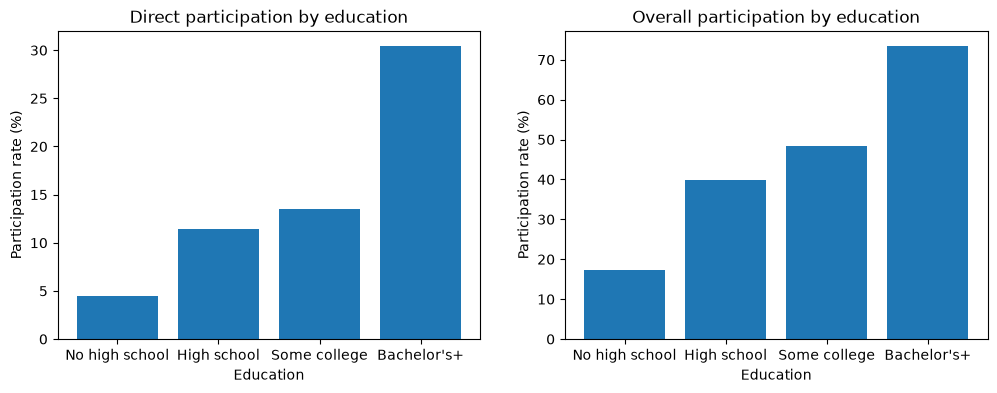

In [ ]:
import matplotlib.pyplot as plt

# 3.1 
educ_levels = [1, 2, 3, 4]
educ_direct = []
educ_overall = []
for educ in educ_levels:
    educ_rows = df[df['educ'] == educ]
    educ_direct.append(participation_rate(educ_rows['direct']))
    educ_overall.append(participation_rate(educ_rows['overall']))

# 3.2 
for i in range(len(educ_levels)):
    print(f'Education {educ_levels[i]}: direct {round(educ_direct[i], 1)} %, overall {round(educ_overall[i], 1)} %')

# 3.3 
educ_labels = ['No high school', 'High school', 'Some college', "Bachelor's+"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(educ_labels, educ_direct)
axes[0].set_title('Direct participation by education')
axes[0].set_xlabel('Education')
axes[0].set_ylabel('Participation rate (%)')

axes[1].bar(educ_labels, educ_overall)
axes[1].set_title('Overall participation by education')
axes[1].set_xlabel('Education')
axes[1].set_ylabel('Participation rate (%)')

plt.show()

Participation increases with education for both measures. Only 4.4% of households without high school own stocks directly, compared to 30.5% of households with a bachelor’s degree or higher. The biggest jump is between “some college” and “bachelor’s or higher”. 

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

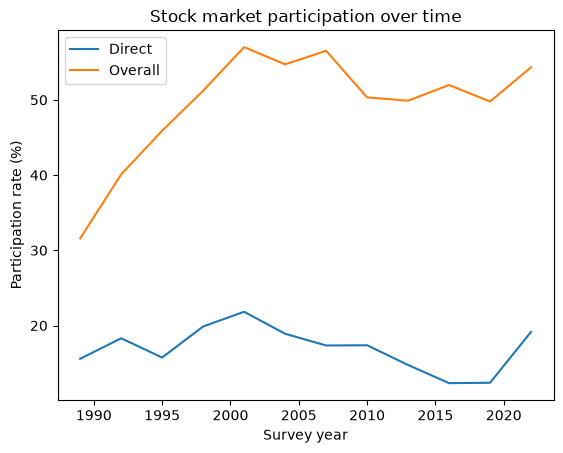

Change 1989-2022 direct: 3.6 percentage points
Change 1989-2022 overall: 22.8 percentage points


In [ ]:
# 4.1 
years = sorted(df['year'].unique())
year_direct = []
year_overall = []
for year in years:
    year_rows = df[df['year'] == year]
    year_direct.append(participation_rate(year_rows['direct']))
    year_overall.append(participation_rate(year_rows['overall']))

# 4.2 
plt.plot(years, year_direct, label='Direct')
plt.plot(years, year_overall, label='Overall')
plt.title('Stock market participation over time')
plt.xlabel('Survey year')
plt.ylabel('Participation rate (%)')
plt.legend()
plt.show()

# 4.3 
change_direct = year_direct[-1] - year_direct[0]
change_overall = year_overall[-1] - year_overall[0]
print(f'Change 1989-2022 direct: {round(change_direct, 1)} percentage points')
print(f'Change 1989-2022 overall: {round(change_overall, 1)} percentage points')

Overall participation increased a lot from 31.6% in 1989 to a peak of 57.0% in 2001, and has stayed around 50–55% since then. Direct participation has been fairly flat, between 12% and 22%, and only increased by 3.6 percentage points from 1989 to 2022. This means most of the increase came from indirect ownership, like mutual funds and retirement accounts.

***
## AI-use statement

I used Claude as a tutor while working on this assignment. For Part 1.1–1.3, Claude explained the concepts and gave hints, and I wrote the code myself (except the `id` and `year` blocks in 1.2). I did the same for the other parts, however these was more challanging and i needed more help. I have walked through all the code, tried my best, and realise this needs more practice. It was really great to learn and use the code in practice, so I will se this method of learning forward. 